## Agentic RAG with MCP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/en/8_6_Agentic_RAG_with_MCP_en.ipynb)

| | |
|---|---|
| 🎯 **What you'll learn** | Expose knowledge sources as MCP servers (tools + resources), let an agent choose sources and search iteratively, then build a controllable agentic-RAG graph in LangGraph: plan → parallel retrieval → grade → re-plan → grounded answer with citations. |
| 🔑 **API keys** | `OPENAI_API_KEY` |
| 💲 **API cost** | low – about 30 short requests |
| ⏱️ **Run time** | ~2–3 min (every MCP tool call starts a local server process) |

### Install libraries

In [1]:
# Install this notebook's direct dependencies.
# Skipped when pip is missing, e.g. in the `uv sync` environment, which already has them (see README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langchain langchain-openai langchain-mcp-adapters fastmcp rank-bm25 python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.

Note: you may need to restart the kernel to use updated packages.


## Classic RAG vs agentic RAG

**Classic RAG** always does the same thing: *one* retriever, *one* search with the user's question, then generate.

```
question ──► retriever ──► top-k chunks ──► LLM ──► answer
```

**Agentic RAG** puts an LLM in charge of retrieval. It decides:

| Decision | Example |
|---|---|
| **Whether** to retrieve at all | "What does MCP stand for?" → answer directly |
| **Which source** to use | policy question → knowledge base, "how much did Anna spend?" → SQL database |
| **How** to query each source | rewrite the question into keywords, or write SQL |
| **Whether the evidence is enough** | missing a number → search again with a refined query (iterative retrieval) |

```
                ┌───────────── not enough, refine ─────────────┐
                ▼                                              │
question ──► plan ──► knowledge base (MCP) ──┐                 │
                 └──► sales database (MCP) ──┴──► grade evidence ──► answer + citations
```

### Why MCP?

The **Model Context Protocol** is an open standard for connecting LLM applications to data and tools. Every source becomes an MCP **server**; the agent connects as a **client**. The same server works with LangChain, Claude Desktop, IDEs or any other MCP client, and can be owned and deployed by the team that owns the data.

| MCP primitive | Controlled by | Used here for |
|---|---|---|
| **Tools** | the model | `search_knowledge_base`, `get_document`, `run_sql`, `describe_schema` |
| **Resources** | the application | `schema://sales` – DB schema injected into the SQL prompt |
| **Prompts** | the user | (templates – not used here) |

## 1. Two MCP servers

### Knowledge base server

Shop policies searched with BM25 (`rank-bm25`). A small chunk is returned by `search_knowledge_base`; `get_document` lets the agent read a whole document when a snippet is not enough. **Tool docstrings matter** – they are what the model reads when it chooses a source.

In [2]:
%%writefile kb_server.py
# ruff: noqa: E501
import re

from fastmcp import FastMCP
from rank_bm25 import BM25Okapi

mcp = FastMCP("knowledge-base")

DOCUMENTS = {
    "returns": "Return policy. Products can be returned within 30 days of delivery if they are unused and in the original packaging. "
    "For hygiene reasons opened headphones and earbuds can be returned only if they are defective. "
    "Refunds are paid within 14 days to the original payment method.",
    "warranty": "Warranty. All electronics have a 24-month warranty. Defective products are repaired, replaced or refunded. "
    "File a claim in the support portal with the order number.",
    "loyalty": "Loyalty program. The tier depends on the total value of DELIVERED orders in the last 12 months "
    "(cancelled and returned orders do not count): Silver from 2,000 EUR, Gold from 5,000 EUR, Platinum from 10,000 EUR. "
    "Silver: free standard shipping. Gold: 5% discount on all orders and free express shipping. "
    "Platinum: 10% discount, free express shipping and a dedicated advisor.",
    "shipping": "Shipping. Standard shipping takes 3-5 business days and costs 9 EUR, free above 200 EUR. "
    "Express shipping delivers the next business day for 25 EUR. We ship to all EU countries.",
    "payments": "Payments. We accept cards, BLIK, PayPal and bank transfers. Invoices are sent by e-mail after shipment.",
    "privacy": "Privacy. Customer data is stored in the EU and kept for 5 years after the last order. "
    "Customers can request a copy or deletion of their data at privacy@shop.example.",
}


def tokenize(text: str) -> list[str]:
    return re.findall(r"\w+", text.lower())


ids = list(DOCUMENTS)
bm25 = BM25Okapi([tokenize(DOCUMENTS[i]) for i in ids])


@mcp.tool()
def search_knowledge_base(query: str, k: int = 2) -> list[dict]:
    """Search the shop's policies (returns, warranty, loyalty program, shipping, payments, privacy).
    Use short keyword queries. Returns the best matching documents with their ids."""
    scores = bm25.get_scores(tokenize(query))
    best = sorted(zip(ids, scores, strict=True), key=lambda pair: pair[1], reverse=True)[:k]
    return [{"doc_id": doc_id, "text": DOCUMENTS[doc_id]} for doc_id, score in best if score > 0]


@mcp.tool()
def get_document(doc_id: str) -> str:
    """Return the full text of one policy document by its id."""
    return DOCUMENTS.get(doc_id, f"Unknown doc_id. Available: {', '.join(ids)}")


if __name__ == "__main__":
    mcp.run(transport="stdio", show_banner=False, log_level="WARNING")

Overwriting kb_server.py


### Sales database server

Customers and orders in SQLite. Giving an LLM SQL access is a **trust boundary**, so the server enforces read-only access twice: it accepts a single `SELECT`, and the connection itself is switched to `PRAGMA query_only`. Errors are returned to the model as text, so the agent can fix its own SQL. The schema is also published as an MCP **resource**.

In [3]:
%%writefile sales_db_server.py
# ruff: noqa: E501
import re
import sqlite3

from fastmcp import FastMCP

mcp = FastMCP("sales-db")

db = sqlite3.connect(":memory:", check_same_thread=False)
db.executescript("""
CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT);
CREATE TABLE orders (
    id INTEGER PRIMARY KEY,
    customer_id INTEGER REFERENCES customers(id),
    order_date TEXT,      -- ISO date YYYY-MM-DD
    product TEXT,
    amount_eur REAL,
    status TEXT           -- delivered | cancelled | returned
);
INSERT INTO customers VALUES
    (1, 'Anna Nowak', 'Krakow'), (2, 'Jan Kowalski', 'Warsaw'),
    (3, 'Maria Wiśniewska', 'Gdańsk'), (4, 'Piotr Zieliński', 'Poznań');
INSERT INTO orders VALUES
    (1, 1, '2026-02-03', 'Laptop', 1800, 'delivered'),
    (2, 1, '2026-05-14', 'Keyboard', 120, 'delivered'),
    (3, 1, '2026-08-30', 'Wireless headphones', 299, 'delivered'),
    (4, 1, '2026-10-02', 'Mouse', 45, 'cancelled'),
    (5, 2, '2025-06-10', 'TV 55', 2500, 'delivered'),
    (6, 2, '2026-01-15', 'Laptop', 2400, 'delivered'),
    (7, 2, '2026-04-02', 'Monitor 27', 900, 'delivered'),
    (8, 2, '2026-09-20', 'Smartphone', 1500, 'delivered'),
    (9, 2, '2026-11-20', 'Wireless headphones', 350, 'returned'),
    (10, 3, '2026-03-03', 'Camera', 3200, 'delivered'),
    (11, 3, '2026-07-07', 'Lens', 2900, 'delivered'),
    (12, 4, '2026-11-01', 'Wireless headphones', 349, 'delivered');
""")
db.execute("PRAGMA query_only = ON")  # defence in depth: the connection cannot write


def schema() -> str:
    return "\n".join(row[0] for row in db.execute("SELECT sql FROM sqlite_master WHERE type = 'table'"))


@mcp.resource("schema://sales")
def schema_resource() -> str:
    """SQL schema of the sales database."""
    return schema()


@mcp.tool()
def describe_schema() -> str:
    """Return the SQL schema of the sales database (customers and orders)."""
    return schema()


@mcp.tool()
def run_sql(query: str) -> list[dict]:
    """Run ONE read-only SQL SELECT on the sales database (customers, orders) and return up to 50 rows. Use it for facts about specific customers, orders, amounts and dates."""
    if not re.match(r"^\s*(select|with)\b", query, re.IGNORECASE) or ";" in query.strip().rstrip(";"):
        raise ValueError("Only a single SELECT query is allowed.")
    cursor = db.execute(query)
    columns = [column[0] for column in cursor.description]
    return [dict(zip(columns, row, strict=True)) for row in cursor.fetchmany(50)]


if __name__ == "__main__":
    mcp.run(transport="stdio", show_banner=False, log_level="WARNING")

Overwriting sales_db_server.py


## 2. Connecting with `MultiServerMCPClient`

`langchain-mcp-adapters` turns the tools of many MCP servers into ordinary LangChain tools. With the `stdio` transport the client starts each server as a subprocess (in production you would typically use `"transport": "streamable_http"` with a URL and auth headers).

In [4]:
import sys

from dotenv import load_dotenv
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_openai import ChatOpenAI

load_dotenv()
llm = ChatOpenAI(model="gpt-6.1-terra", reasoning_effort="none")
TODAY = "2026-11-25"  # fixed, so that "last 12 months" gives the same answer whenever you run the notebook

client = MultiServerMCPClient(
    {
        "knowledge_base": {"transport": "stdio", "command": sys.executable, "args": ["kb_server.py"]},
        "sales_db": {"transport": "stdio", "command": sys.executable, "args": ["sales_db_server.py"]},
    }
)
tools = await client.get_tools()
for t in tools:
    print(f"🔧 {t.name}: {t.description.splitlines()[0]}")

🔧 search_knowledge_base: Search the shop's policies (returns, warranty, loyalty program, shipping, payments, privacy).
🔧 get_document: Return the full text of one policy document by its id.
🔧 describe_schema: Return the SQL schema of the sales database (customers and orders).
🔧 run_sql: Run ONE read-only SQL SELECT on the sales database (customers, orders) and return up to 50 rows. Use it for facts about specific customers, orders, amounts and dates.


Tools can be called directly, too. MCP returns a list of content blocks; the read-only guard is visible in the last call:

In [5]:
tool = {t.name: t for t in tools}


def text_of(result) -> str:
    return "\n".join(block["text"] for block in result if block["type"] == "text")


print(text_of(await tool["search_knowledge_base"].ainvoke({"query": "return opened headphones"})))
print(text_of(await tool["run_sql"].ainvoke({"query": "SELECT status, COUNT(*) AS n FROM orders GROUP BY status"})))
print(text_of(await tool["run_sql"].ainvoke({"query": "DELETE FROM orders"})))

[{"doc_id":"returns","text":"Return policy. Products can be returned within 30 days of delivery if they are unused and in the original packaging. For hygiene reasons opened headphones and earbuds can be returned only if they are defective. Refunds are paid within 14 days to the original payment method."}]
[{"status":"cancelled","n":1},{"status":"delivered","n":10},{"status":"returned","n":1}]
Error calling tool 'run_sql': Only a single SELECT query is allowed.


And the schema **resource** – read by the application, not chosen by the model:

In [6]:
resources = await client.get_resources("sales_db", uris=["schema://sales"])
SCHEMA = resources[0].as_string()
print(SCHEMA)

CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT)
CREATE TABLE orders (
    id INTEGER PRIMARY KEY,
    customer_id INTEGER REFERENCES customers(id),
    order_date TEXT,      -- ISO date YYYY-MM-DD
    product TEXT,
    amount_eur REAL,
    status TEXT           -- delivered | cancelled | returned
)


## 3. Agentic RAG v1 – a tool-calling agent chooses the sources

The simplest agentic RAG: give `create_agent` all MCP tools and a system prompt that describes the sources. The agent loop (*reason → call tool → observe → …*) gives us source selection and iterative retrieval for free.

In [7]:
import json

from langchain.agents import create_agent

SYSTEM_PROMPT = f"""You are a customer-support assistant of an online electronics shop. Today is {TODAY}.
Sources:
- knowledge base tools: shop policies (returns, warranty, loyalty program, shipping, payments, privacy)
- sales database tools: facts about specific customers and their orders
Rules:
- Use only the sources that the question needs; answer general questions without tools.
- For facts about a customer, query the database (check the schema first if unsure).
- If the evidence is incomplete, search again with a refined query or a different source.
- Answer briefly and cite sources, e.g. [kb:loyalty] or [sql]."""

rag_agent = create_agent(llm, tools=tools, system_prompt=SYSTEM_PROMPT)


async def ask(question: str) -> None:
    result = await rag_agent.ainvoke({"messages": [{"role": "user", "content": question}]})
    print(f"❓ {question}")
    for message in result["messages"]:
        for call in getattr(message, "tool_calls", []):
            print(f"   🔧 {call['name']}({json.dumps(call['args'], ensure_ascii=False)})")
    print(f"💬 {result['messages'][-1].text}\n")

Four questions, four different retrieval strategies – watch which tools the agent picks:

In [8]:
for question in [
    "What does the abbreviation MCP stand for?",                                      # no retrieval
    "Can I return wireless headphones I have already opened? They work fine.",        # knowledge base
    "How many orders did Anna Nowak place in 2026 and what was their total value?",   # SQL
    "Which loyalty tier does Jan Kowalski have and what benefits does he get?",       # both, multi-hop
]:
    await ask(question)

❓ What does the abbreviation MCP stand for?
💬 MCP can stand for several things. In AI, it usually means **Model Context Protocol**.

❓ Can I return wireless headphones I have already opened? They work fine.
   🔧 search_knowledge_base({"query": "returns opened wireless headphones working hygiene", "k": 3})
💬 No. For hygiene reasons, opened headphones can only be returned if they’re defective. Since yours work fine, they aren’t eligible for a return. [kb:returns]

❓ How many orders did Anna Nowak place in 2026 and what was their total value?
   🔧 describe_schema({})
   🔧 run_sql({"query": "SELECT c.id, c.name, COUNT(o.id) AS order_count, COALESCE(SUM(o.amount_eur), 0) AS total_eur FROM customers c LEFT JOIN orders o ON o.customer_id = c.id AND o.order_date >= '2026-01-01' AND o.order_date < '2027-01-01' WHERE c.name = 'Anna Nowak' GROUP BY c.id, c.name"})
💬 Anna Nowak placed **4 orders** in 2026, with a total value of **€2,264**. [sql]

❓ Which loyalty tier does Jan Kowalski have and wha

The last question is **multi-hop**: the agent must first learn the rule (*delivered orders, last 12 months*) from the knowledge base and then compute the right sum in SQL. Jan's data contains three traps: a TV bought more than 12 months ago, a returned pair of headphones, and a total just below the Gold threshold. The correct answer is **Silver** (2400 + 900 + 1500 = 4800 EUR).

The agent is flexible, but the control flow lives in the prompt – hard to test, hard to guarantee. When you need guarantees, make the loop explicit.

## 4. Agentic RAG v2 – an explicit LangGraph loop

Same MCP servers, but now **we** define the steps and the LLM only makes decisions inside them:

| Node | Decision made by the LLM | Guarantee from the graph |
|---|---|---|
| `plan` | which sources, which queries (structured output) | at least one plan before answering |
| `search_kb`, `query_db` | the SQL text | sources run **in parallel** (`Send`), SQL always gets the schema resource |
| `grade` | is the evidence sufficient? what is missing? | at most `MAX_ROUNDS` retrieval rounds |
| `answer` | the final wording | answers only from collected evidence, with citations |

In [9]:
import operator
from typing import Annotated, TypedDict

from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field

MAX_ROUNDS = 3


class Plan(BaseModel):
    kb_queries: list[str] = Field(default_factory=list, description="Keyword queries for the policy knowledge base; empty if not needed")
    db_tasks: list[str] = Field(default_factory=list, description="Data questions to answer with SQL; empty if not needed")


class Grade(BaseModel):
    sufficient: bool = Field(description="True if the evidence fully answers the question")
    missing: str = Field(description="What is still missing; empty if sufficient")


class RagState(TypedDict, total=False):
    question: str
    plan: Plan
    evidence: Annotated[list[str], operator.add]  # parallel searches append here
    rounds: int
    feedback: str
    answer: str


async def plan(state: RagState) -> RagState:
    prompt = (
        f"Today is {TODAY}. Plan retrieval for the question below.\n"
        "Sources: knowledge base = shop policies; database = customers and orders.\n"
        "Return empty lists if the question needs no shop data.\n"
        f"Question: {state['question']}\n"
        f"Evidence so far:\n{chr(10).join(state.get('evidence', [])) or '-'}\n"
        f"Missing according to the grader: {state.get('feedback') or '-'}"
    )
    return {"plan": await llm.with_structured_output(Plan).ainvoke(prompt), "rounds": state.get("rounds", 0) + 1}


def dispatch(state: RagState) -> list[Send] | str:
    sends = [Send("search_kb", {"query": q}) for q in state["plan"].kb_queries]
    sends += [Send("query_db", {"task": t}) for t in state["plan"].db_tasks]
    return sends or "answer"  # nothing to retrieve -> answer directly


async def search_kb(task: dict) -> RagState:
    result = text_of(await tool["search_knowledge_base"].ainvoke({"query": task["query"]}))
    return {"evidence": [f"[kb] query={task['query']!r}\n{result}"]}


async def query_db(task: dict) -> RagState:
    sql = (await llm.ainvoke(
        f"Today is {TODAY}. Write ONE SQLite SELECT query for this task. Return only SQL, no markdown.\n"
        f"Schema:\n{SCHEMA}\nTask: {task['task']}"
    )).text.strip()
    result = text_of(await tool["run_sql"].ainvoke({"query": sql}))  # errors come back as text, too
    return {"evidence": [f"[sql] task={task['task']!r}\n{sql}\n-> {result}"]}


async def grade(state: RagState) -> RagState:
    verdict = await llm.with_structured_output(Grade).ainvoke(
        f"Question: {state['question']}\nEvidence:\n{chr(10).join(state['evidence'])}\n"
        "Is this evidence sufficient to answer the question correctly and completely? Check that SQL results "
        "follow every rule found in the policies (dates, statuses, thresholds)."
    )
    return {"feedback": "" if verdict.sufficient else verdict.missing}


def after_grade(state: RagState) -> str:
    return "answer" if not state["feedback"] or state["rounds"] >= MAX_ROUNDS else "plan"


async def answer(state: RagState) -> RagState:
    response = await llm.ainvoke(
        f"Answer the customer's question using ONLY the evidence. Cite [kb:<doc_id>] or [sql]. "
        f"If there is no evidence, answer from general knowledge and say so.\n"
        f"Question: {state['question']}\nEvidence:\n{chr(10).join(state.get('evidence', [])) or '-'}"
    )
    return {"answer": response.text}


builder = StateGraph(RagState)
for node in (plan, search_kb, query_db, grade, answer):
    builder.add_node(node)
builder.add_edge(START, "plan")
builder.add_conditional_edges("plan", dispatch, ["search_kb", "query_db", "answer"])
builder.add_edge("search_kb", "grade")
builder.add_edge("query_db", "grade")
builder.add_conditional_edges("grade", after_grade, ["plan", "answer"])
builder.add_edge("answer", END)
agentic_rag = builder.compile()

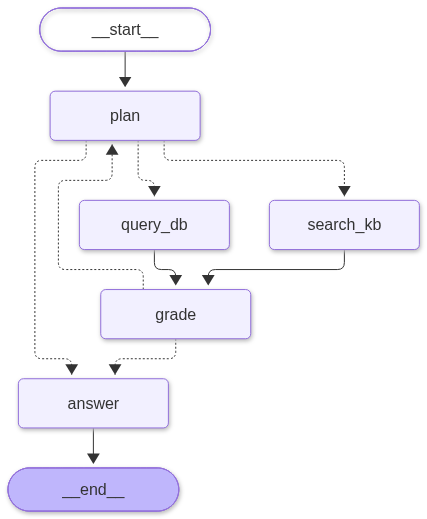

In [10]:
from IPython.display import Image

Image(agentic_rag.get_graph().draw_mermaid_png())

`astream(..., stream_mode="updates")` shows every step as it happens – the plan, each parallel retrieval, the grader's verdict and possible extra rounds:

In [11]:
async def run(question: str) -> None:
    print(f"❓ {question}")
    async for update in agentic_rag.astream({"question": question}, stream_mode="updates"):
        for node, change in update.items():
            if node == "plan":
                p = change["plan"]
                print(f"🧭 plan (round {change['rounds']}): kb={p.kb_queries} db={p.db_tasks}")
            elif node in ("search_kb", "query_db"):
                print(f"🔎 {node}: {change['evidence'][0][:300]}")
            elif node == "grade":
                print(f"⚖️  grade: {'sufficient' if not change['feedback'] else 'missing → ' + change['feedback']}")
            elif node == "answer":
                print(f"💬 {change['answer']}\n")


await run("Which loyalty tier does Jan Kowalski have and what benefits does he get?")

❓ Which loyalty tier does Jan Kowalski have and what benefits does he get?
🧭 plan (round 1): kb=['loyalty tier benefits'] db=["Find Jan Kowalski's current loyalty tier in the customer database."]
🔎 search_kb: [kb] query='loyalty tier benefits'
[{"doc_id":"loyalty","text":"Loyalty program. The tier depends on the total value of DELIVERED orders in the last 12 months (cancelled and returned orders do not count): Silver from 2,000 EUR, Gold from 5,000 EUR, Platinum from 10,000 EUR. Silver: free standard shi
🔎 query_db: [sql] task="Find Jan Kowalski's current loyalty tier in the customer database."
SELECT c.id, c.name, NULL AS loyalty_tier
FROM customers AS c
WHERE c.name = 'Jan Kowalski';
-> [{"id":2,"name":"Jan Kowalski","loyalty_tier":null}]
⚖️  grade: missing → Jan Kowalski’s total value of DELIVERED orders in the last 12 months is needed to determine his tier and benefits. Cancelled and returned orders must be excluded; the NULL tier result does not establish his tier.
🧭 plan (round 2

In [12]:
await run("Piotr Zieliński wants to return the wireless headphones he bought this month. He opened them and they work. Is it possible?")
await run("What does the abbreviation MCP stand for?")

❓ Piotr Zieliński wants to return the wireless headphones he bought this month. He opened them and they work. Is it possible?
🧭 plan (round 1): kb=['return policy opened working wireless headphones change of mind eligibility return window exceptions'] db=["Find Piotr Zieliński's wireless headphone purchase orders in November 2026, including purchase date, delivery date, order status, and product details needed to assess return eligibility."]
🔎 search_kb: [kb] query='return policy opened working wireless headphones change of mind eligibility return window exceptions'
[{"doc_id":"returns","text":"Return policy. Products can be returned within 30 days of delivery if they are unused and in the original packaging. For hygiene reasons opened headphones an
🔎 query_db: [sql] task="Find Piotr Zieliński's wireless headphone purchase orders in November 2026, including purchase date, delivery date, order status, and product details needed to assess return eligibility."
SELECT
    o.order_date AS p